In [1]:
#lesson 1

In [2]:
#notes
'''
derivs: how do functions respond (sensitivity) to small changes in value)

In [3]:
#implementation

In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
def f(x):
    return 3*x**2 - 4*x + 5

In [7]:
f(3.0)

20.0

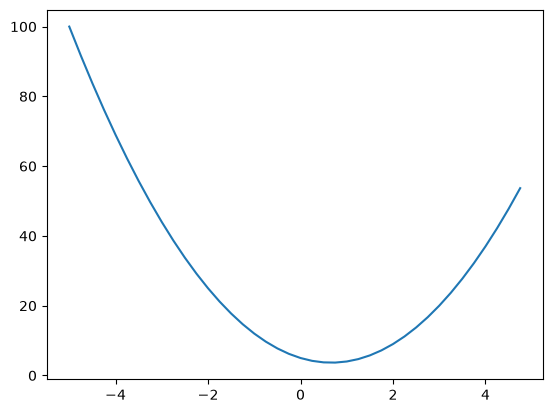

In [9]:
xs = np.arange(-5,5,.25)
ys = f(xs)
plt.plot(xs, ys)

In [133]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other*(self.data**(other-1))) * out.grad
        out._backward = _backward
        return out
    
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1
    
    def __sub__(self, other):
        return self + (-other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad=1.0
        for node in reversed(topo):
            node._backward()

In [47]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [77]:
x1 = Value(2.3, label ='x1')
x2 = Value(0.2, label ='x2')
w1 = Value(-1.5, label ='w1')
w2 = Value(0.75, label = 'w2')
b = Value(7, label = 'b')
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

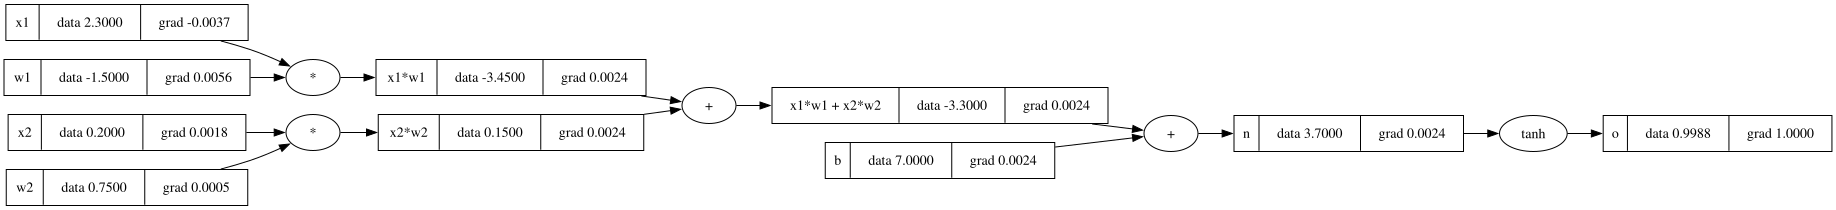

In [80]:
draw_dot(o)

In [79]:
o.backward()

In [134]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(np.random.uniform(-1,1)) for _ in range (nin)]
        self.b = Value(np.random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

In [135]:
class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

In [136]:
class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range (len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [154]:
x = [1.0, -2.0, 3.0]
n = MLP(3, [4,4,1])

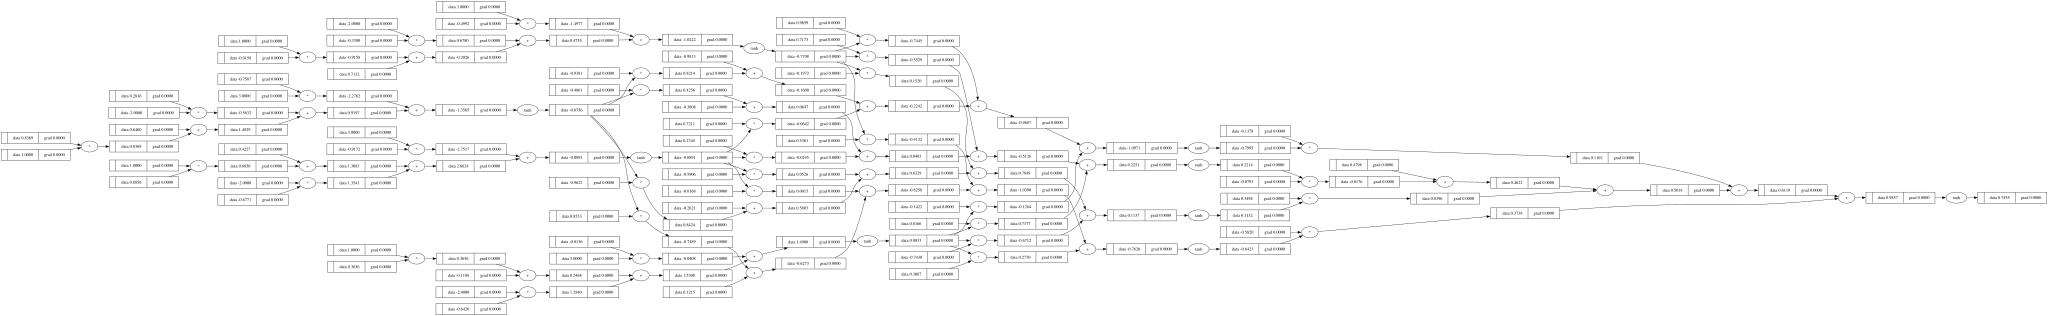

In [101]:
draw_dot(n(x))

In [106]:
n.parameters()

[Value(data=0.914018548084091),
 Value(data=0.44126957934239197),
 Value(data=0.9127652867288707),
 Value(data=0.9754309024225447),
 Value(data=0.16726001664818413),
 Value(data=-0.3235957216891392),
 Value(data=0.3974142412550652),
 Value(data=-0.052093265383585274),
 Value(data=-0.8690911097191791),
 Value(data=-0.08645289412123369),
 Value(data=0.23689285099793222),
 Value(data=-0.7726359130602454),
 Value(data=0.9204937380199067),
 Value(data=0.18534988624520676),
 Value(data=0.6405718699084497),
 Value(data=0.6052087526832906),
 Value(data=0.025019413633083465),
 Value(data=0.26184300560763596),
 Value(data=0.537931970604371),
 Value(data=-0.5900982515567286),
 Value(data=-0.5482257787126095),
 Value(data=-0.452583112697738),
 Value(data=0.930089021262039),
 Value(data=0.6013318971931778),
 Value(data=0.7924494213232924),
 Value(data=0.7846874405071378),
 Value(data=-0.601400689364747),
 Value(data=-0.6261251973242059),
 Value(data=0.9065169795693993),
 Value(data=-0.8969703440081

In [144]:
xs = [
    [1.0,1.5,-2.0],
    [2.3, 1.2, -3.2],
    [-1.0, 1.0, 1.1],
    [0.3, 0.6, 0.8]
]
ys = [1.0, -1.0, -1.0, 1.0]

In [145]:
ypred = [n(x) for x in xs]

In [146]:
loss = sum((ypred - ytrue)**2 for ytrue, ypred in zip(ys, ypred))
loss

Value(data=4.417191836745371)

In [151]:
loss.backward()

In [152]:
for p in n.parameters():
    p.data += -0.01 * p.grad

In [153]:
ypred = [n(x) for x in xs]
loss = sum((ypred - ytrue)**2 for ytrue, ypred in zip(ys, ypred))
loss

Value(data=4.181586230951186)

In [159]:
for k in range (50):
    ypred = [n(x) for x in xs]
    loss = sum((ypred - ytrue)**2 for ytrue, ypred in zip(ys, ypred))

    for p in n.parameters():
        p.grad = 0.0
        
    loss.backward()

    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 4.000016118968197
1 4.000016117933318
2 4.000016116898572
3 4.000016115863959
4 4.000016114829479
5 4.000016113795131
6 4.000016112760917
7 4.000016111726834
8 4.000016110692884
9 4.000016109659067
10 4.000016108625382
11 4.00001610759183
12 4.0000161065584106
13 4.000016105525123
14 4.000016104491968
15 4.000016103458946
16 4.0000161024260565
17 4.000016101393299
18 4.000016100360673
19 4.000016099328181
20 4.00001609829582
21 4.000016097263591
22 4.000016096231495
23 4.000016095199531
24 4.000016094167699
25 4.000016093136
26 4.000016092104432
27 4.000016091072997
28 4.000016090041694
29 4.000016089010522
30 4.000016087979483
31 4.000016086948576
32 4.0000160859178004
33 4.000016084887157
34 4.0000160838566465
35 4.000016082826266
36 4.000016081796019
37 4.000016080765904
38 4.00001607973592
39 4.000016078706068
40 4.000016077676348
41 4.000016076646759
42 4.000016075617302
43 4.000016074587977
44 4.0000160735587835
45 4.000016072529721
46 4.0000160715007915
47 4.000016070471993
48

In [160]:
print("Loss:", loss.data)

print("\nPredictions:")
for x, y in zip(xs, ys):
    print(f"Target: {y:+.1f}, Prediction: {n(x).data:+.6f}")

print("\nGradients:")
print("Max:", max(abs(p.grad) for p in n.parameters()))
print("Mean:", sum(abs(p.grad) for p in n.parameters()) / len(n.parameters()))

Loss: 4.000016068414791

Predictions:
Target: +1.0, Prediction: -1.000000
Target: -1.0, Prediction: -1.000000
Target: -1.0, Prediction: -0.995992
Target: +1.0, Prediction: +1.000000

Gradients:
Max: 6.414483730735487e-05
Mean: 7.846659573632703e-06


In [ ]:
#lol insane tanh saturation, prob need to reinit network for it to work